MAS Assignment 3

In [1]:
import functools
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

N = 20
NAME = "ARKA"
rng = np.random.default_rng(12001)

def er_connected_graph(n, p, rng):
    while True:
        G = nx.erdos_renyi_graph(n, p, seed=int(rng.integers(0, 1 << 30)))
        if nx.is_connected(G):
            return G

G = er_connected_graph(N, p=0.1, rng=rng)
Lap = nx.laplacian_matrix(G).toarray().astype(float)
print("connected:", nx.is_connected(G), "| edges:", G.number_of_edges())


connected: True | edges: 32


Letters: hand-defined single-stroke polylines, 20 points sampled at equal arc-length per letter. Control law: $\dot{x} = -L(x-d)$, $L$ = graph Laplacian, $d$ = target. Centroid is preserved, so $x_0$ is recentered to match.

In [2]:
STROKES = {
    "A": [
        [(0, 0), (0.5, 1.4), (1, 0)],
        [(0.22, 0.5), (0.78, 0.5)],
    ],
    "R": [
        [(0, 0), (0, 1.4)],
        [(0, 1.4), (0.75, 1.4), (0.85, 1.15), (0.75, 0.9), (0, 0.9)],
        [(0.35, 0.9), (0.9, 0)],
    ],
    "K": [
        [(0, 0), (0, 1.4)],
        [(0.85, 1.4), (0, 0.75)],
        [(0.15, 0.9), (0.85, 0)],
    ],
}

@functools.lru_cache(maxsize=None)
def letter_strokes_and_points(letter, n_points, scale):
    strokes = [np.array(s) * scale for s in STROKES[letter]]
    center = np.concatenate(strokes).mean(axis=0)
    strokes = [s - center for s in strokes]

    edges = [(p0, p1, np.linalg.norm(p1 - p0)) for s in strokes for p0, p1 in zip(s[:-1], s[1:])]
    total_len = sum(e[2] for e in edges)
    targets = np.linspace(0, total_len, n_points, endpoint=False)

    pts, cum, ti = [], 0.0, 0
    for p0, p1, seglen in edges:
        seg_start = cum
        cum += seglen
        while ti < len(targets) and targets[ti] <= cum:
            t = 0.0 if seglen == 0 else (targets[ti] - seg_start) / seglen
            pts.append(p0 + t * (p1 - p0))
            ti += 1
    return np.array(pts[:n_points]), strokes

def simulate(x_start, d_target, Lap, steps, dt):
    traj = np.zeros((steps + 1, *x_start.shape))
    traj[0] = x_start
    for k in range(steps):
        traj[k + 1] = traj[k] + dt * (-Lap @ (traj[k] - d_target))
    return traj

letter_size = 4.0
letters = [letter_strokes_and_points(ch, N, letter_size) for ch in NAME]
formations = [pts for pts, _ in letters]

x0 = rng.uniform(-5, 5, size=(N, 2))
x0 -= x0.mean(axis=0)  # Laplacian feedback conserves the centroid; match it to the (0,0)-centered letters

steps_per_letter, dt = 150, 0.05
segments = [x0[None, :, :]]
x_cur = x0
for d_target in formations:
    traj = simulate(x_cur, d_target, Lap, steps_per_letter, dt)
    segments.append(traj[1:])
    x_cur = traj[-1]
full_traj = np.concatenate(segments, axis=0)
print("full_traj shape:", full_traj.shape)


full_traj shape: (601, 20, 2)


In [3]:
fig, ax = plt.subplots(figsize=(5, 5), dpi=80)
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect("equal")
ax.set_title(f"Formation control: spelling '{NAME}' (N={N} agents, ER graph)")

edges = list(G.edges())
edge_lines = [ax.plot([], [], color="gray", lw=0.5, zorder=1)[0] for _ in edges]
scat = ax.scatter([], [], s=60, c="crimson", zorder=2)
letter_text = ax.text(0.02, 0.96, "", transform=ax.transAxes, fontsize=14, va="top")
max_strokes = max(len(strokes) for _, strokes in letters)
guide_lines = [ax.plot([], [], color="lightgray", lw=6, solid_capstyle="round", zorder=0)[0] for _ in range(max_strokes)]

frame_stride = 5
frames_idx = np.arange(0, len(full_traj), frame_stride)
letter_boundaries = np.cumsum([0] + [steps_per_letter] * len(formations))

def which_letter_idx(frame):
    for i, boundary in enumerate(letter_boundaries[1:]):
        if frame <= boundary:
            return i
    return len(NAME) - 1

def update(frame_i):
    frame = frames_idx[frame_i]
    idx = which_letter_idx(frame)
    pos = full_traj[frame]
    scat.set_offsets(pos)
    for line, (i, j) in zip(edge_lines, edges):
        line.set_data([pos[i, 0], pos[j, 0]], [pos[i, 1], pos[j, 1]])
    letter_text.set_text(f"target: {NAME[idx]}")

    _, strokes = letters[idx]
    for line, stroke in zip(guide_lines, strokes):
        line.set_data(stroke[:, 0], stroke[:, 1])
    for line in guide_lines[len(strokes):]:
        line.set_data([], [])
    return [*guide_lines, scat, letter_text, *edge_lines]

anim = FuncAnimation(fig, update, frames=len(frames_idx), interval=30, blit=True)
anim.save("arka_formation.mp4", writer=FFMpegWriter(fps=30, extra_args=["-preset", "ultrafast"]))
plt.close(fig)
print("saved arka_formation.mp4")


saved arka_formation.mp4


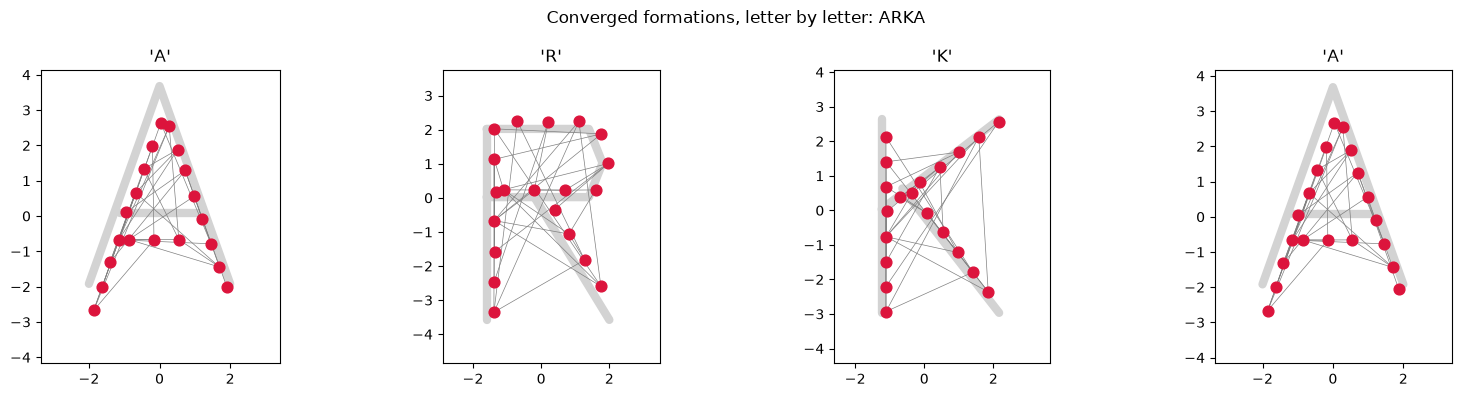

In [4]:
fig, axes = plt.subplots(1, len(NAME), figsize=(4 * len(NAME), 4))
for ax, ch, frame, (_, strokes) in zip(axes, NAME, letter_boundaries[1:], letters):
    pos = full_traj[frame]
    for stroke in strokes:
        ax.plot(stroke[:, 0], stroke[:, 1], color="lightgray", lw=6, solid_capstyle="round", zorder=0)
    for i, j in edges:
        ax.plot([pos[i, 0], pos[j, 0]], [pos[i, 1], pos[j, 1]], color="gray", lw=0.5, zorder=1)
    ax.scatter(pos[:, 0], pos[:, 1], s=60, c="crimson", zorder=2)
    ax.set_title(f"'{ch}'")
    ax.set_aspect("equal")
    ax.set_xlim(pos[:, 0].min() - 1.5, pos[:, 0].max() + 1.5)
    ax.set_ylim(pos[:, 1].min() - 1.5, pos[:, 1].max() + 1.5)

fig.suptitle(f"Converged formations, letter by letter: {NAME}")
fig.tight_layout()
plt.show()
